In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folder containing your exported EDA tables
table_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

# All exported analysis table names
table_names = [
    "order_analysis",
    "order_revenue",
    "sales_data",
    "monthly_aov",
    "status_analysis",
    "product_analysis",
    "product_sales",
    "customer_analysis",
    "customer_orders",
    "customer_order_counts",
    "customer_spending",
    "customer_geography",
    "seller_analysis",
    "seller_performance",
    "top_sellers",
    "top_revenue_sellers",
    "payment_methods",
    "payment_value_analysis",
    "installment_analysis",
    "delivery_data",
    "delivered_orders",
    "delivery_status_summary",
    "delivery_by_state",
    "review_data",
    "review_distribution",
    "order_reviews",
    "category_review_summary",
    "delivery_review_summary",
    "customers_by_state",
    "sellers_by_state",
    "revenue_by_state",
    "customer_seller_comparison"
]

# Load every table that exists
loaded_tables = {}
missing_tables = []

for name in table_names:
    file_path = table_dir / f"{name}.csv"

    if file_path.exists():
        loaded_tables[name] = pd.read_csv(file_path)
    else:
        missing_tables.append(name)

# Create a separate variable for each loaded table
globals().update(loaded_tables)

print(f"Successfully loaded: {len(loaded_tables)} tables")

if missing_tables:
    print("\nFiles not found:")
    for name in missing_tables:
        print(f"- {name}.csv")
else:
    print("All listed tables were found.")

Successfully loaded: 32 tables
All listed tables were found.


In [5]:
orders = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_orders_dataset.csv")

customers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_customers_dataset.csv")

order_items = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_items_dataset.csv")

products = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_products_dataset.csv")

sellers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_sellers_dataset.csv")

payments = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_payments_dataset.csv")

reviews = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_reviews_dataset.csv")

geolocation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_geolocation_dataset.csv")

category_translation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\product_category_name_translation.csv")

In [2]:
table_summary = pd.DataFrame([
    {
        "table_name": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    }
    for name, df in loaded_tables.items()
])

table_summary

,table_name,rows,columns
0,order_analysis,99441,11
1,order_revenue,98666,2
2,sales_data,98666,4
3,monthly_aov,24,4
4,status_analysis,8,3
5,product_analysis,32951,13
6,product_sales,32951,5
7,customer_analysis,99441,8
8,customer_orders,99441,7
9,customer_order_counts,96096,2


## Descriptive Statistics

In [3]:

sales_stats = order_analysis["total_order_value"].describe()

print("Sales and Order Value Statistics")
display(sales_stats)

print("\nAdditional Measures")
print(
    "Median:",
    round(order_analysis["total_order_value"].median(), 2)
)
print(
    "Variance:",
    round(order_analysis["total_order_value"].var(), 2)
)
print(
    "Skewness:",
    round(order_analysis["total_order_value"].skew(), 2)
)


Sales and Order Value Statistics


count    98666.000000
mean       137.754076
std        210.645145
min          0.850000
25%         45.900000
50%         86.900000
75%        149.900000
max      13440.000000
Name: total_order_value, dtype: float64


Additional Measures
Median: 86.9
Variance: 44371.38
Skewness: 9.73


In [6]:

product_price_stats = order_items["price"].describe()

print("Product Price Statistics")
display(product_price_stats)

print("\nAdditional Measures")
print("Median Price:", round(order_items["price"].median(), 2))
print("Price Variance:", round(order_items["price"].var(), 2))
print("Price Skewness:", round(order_items["price"].skew(), 2))

Product Price Statistics


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64


Additional Measures
Median Price: 74.99
Price Variance: 33721.42
Price Skewness: 7.92


In [7]:

customer_stats = customer_spending["total_spending"].describe()

print("Customer Spending Statistics")
display(customer_stats)

print("\nAdditional Measures")
print(
    "Median Spending:",
    round(customer_spending["total_spending"].median(), 2)
)
print(
    "Spending Variance:",
    round(customer_spending["total_spending"].var(), 2)
)
print(
    "Spending Skewness:",
    round(customer_spending["total_spending"].skew(), 2)
)


Customer Spending Statistics


count    95420.000000
mean       142.440198
std        217.656355
min          0.850000
25%         47.900000
50%         89.900000
75%        155.000000
max      13440.000000
Name: total_spending, dtype: float64


Additional Measures
Median Spending: 89.9
Spending Variance: 47374.29
Spending Skewness: 9.61


In [8]:

delivery_stats = delivered_orders["delivery_days"].describe()

print("Delivery Time Statistics")
display(delivery_stats)

print("\nAdditional Measures")
print(
    "Median Delivery Days:",
    round(delivered_orders["delivery_days"].median(), 2)
)
print(
    "Delivery Time Variance:",
    round(delivered_orders["delivery_days"].var(), 2)
)
print(
    "Delivery Time Skewness:",
    round(delivered_orders["delivery_days"].skew(), 2)
)


Delivery Time Statistics


count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64


Additional Measures
Median Delivery Days: 10.22
Delivery Time Variance: 91.13
Delivery Time Skewness: 3.83


In [9]:

review_stats = review_data["review_score"].describe()

print("Customer Review Statistics")
display(review_stats)

print("\nAdditional Measures")
print(
    "Median Review Score:",
    round(review_data["review_score"].median(), 2)
)
print(
    "Review Score Standard Deviation:",
    round(review_data["review_score"].std(), 2)
)
print(
    "Review Score Skewness:",
    round(review_data["review_score"].skew(), 2)
)


Customer Review Statistics


count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64


Additional Measures
Median Review Score: 5.0
Review Score Standard Deviation: 1.35
Review Score Skewness: -1.36


In [12]:
descriptive_summary = pd.DataFrame({
    "Metric": [
        "Order Value",
        "Product Price",
        "Customer Spending",
        "Delivery Days",
        "Review Score"
    ],
    "Mean": [
        order_analysis["total_order_value"].mean(),
        order_items["price"].mean(),
        customer_spending["total_spending"].mean(),
        delivered_orders["delivery_days"].mean(),
        review_data["review_score"].mean()
    ],
    "Median": [
        order_analysis["total_order_value"].median(),
        order_items["price"].median(),
        customer_spending["total_spending"].median(),
        delivered_orders["delivery_days"].median(),
        review_data["review_score"].median()
    ],
    "Standard Deviation": [
        order_analysis["total_order_value"].std(),
        order_items["price"].std(),
        customer_spending["total_spending"].std(),
        delivered_orders["delivery_days"].std(),
        review_data["review_score"].std()
    ],
    "Skewness": [
        order_analysis["total_order_value"].skew(),
        order_items["price"].skew(),
        customer_spending["total_spending"].skew(),
        delivered_orders["delivery_days"].skew(),
        review_data["review_score"].skew()
    ]
})

display(descriptive_summary.round(2))

,Metric,Mean,Median,Standard Deviation,Skewness
0,Order Value,137.75,86.90,210.65,9.73
1,Product Price,120.65,74.99,183.63,7.92
2,Customer Spending,142.44,89.90,217.66,9.61
3,Delivery Days,12.56,10.22,9.55,3.83
4,Review Score,4.09,5.00,1.35,-1.36


In [13]:
from pathlib import Path

output_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "descriptive_statistics_summary.csv"

descriptive_summary.to_csv(output_file, index=False)

print("File saved successfully at:")
print(output_file.resolve())

File saved successfully at:
C:\Users\LATO\Documents\Sales Analysis\Analysis Tables\descriptive_statistics_summary.csv


### Distribution Analysis and Visualizations

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

analysis_variables = {
    "Order Value": order_analysis["total_order_value"].dropna(),
    "Product Price": order_items["price"].dropna(),
    "Customer Spending": customer_spending["total_spending"].dropna(),
    "Delivery Days": delivered_orders["delivery_days"].dropna()
}

for name, values in analysis_variables.items():
    print(f"{name}: {len(values):,} observations")

Order Value: 98,666 observations
Product Price: 112,650 observations
Customer Spending: 95,420 observations
Delivery Days: 96,470 observations


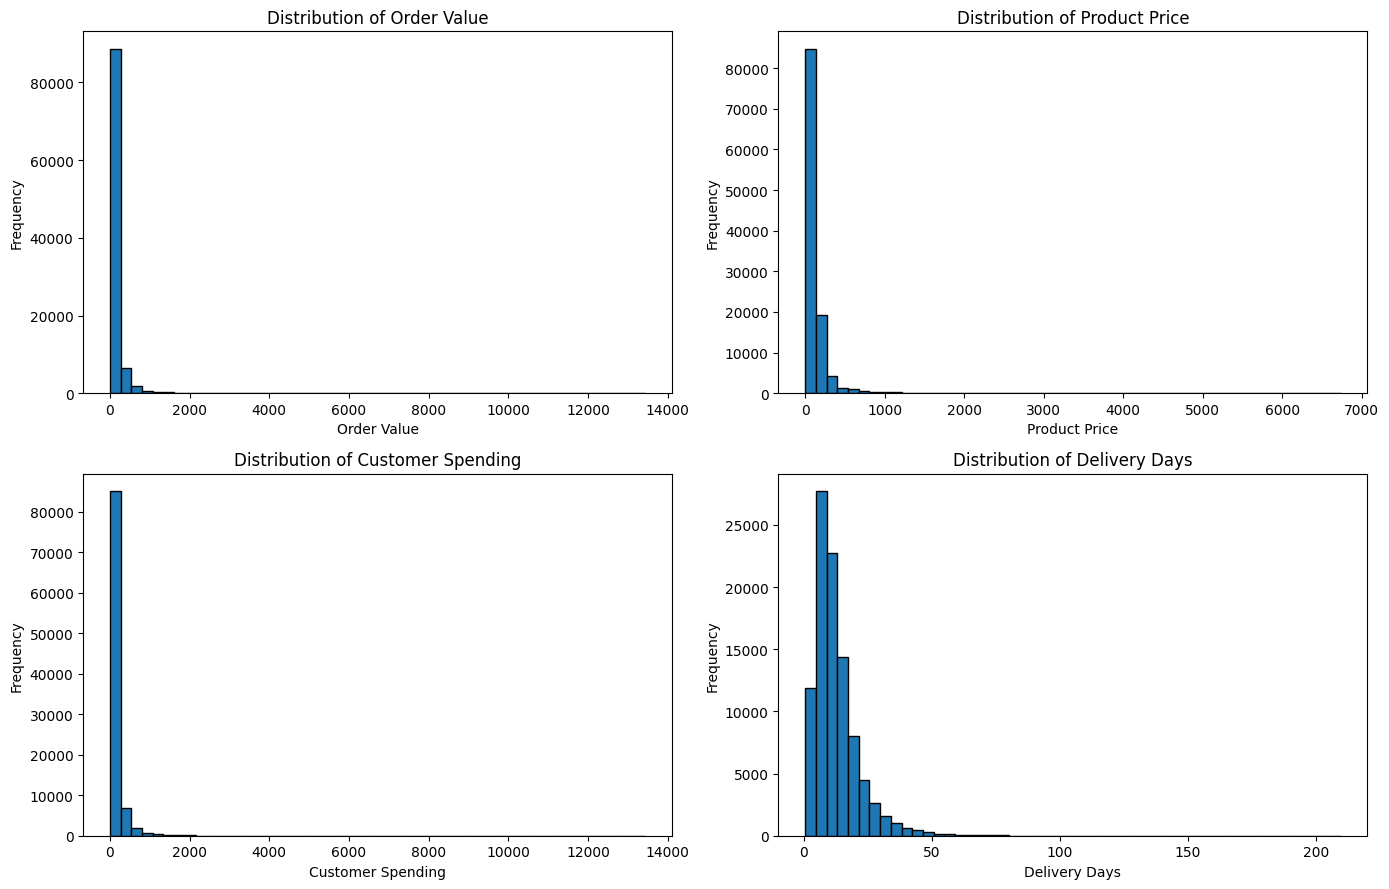

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (name, values) in zip(axes.flatten(), analysis_variables.items()):
    ax.hist(values, bins=50, edgecolor="black")
    ax.set_title(f"Distribution of {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

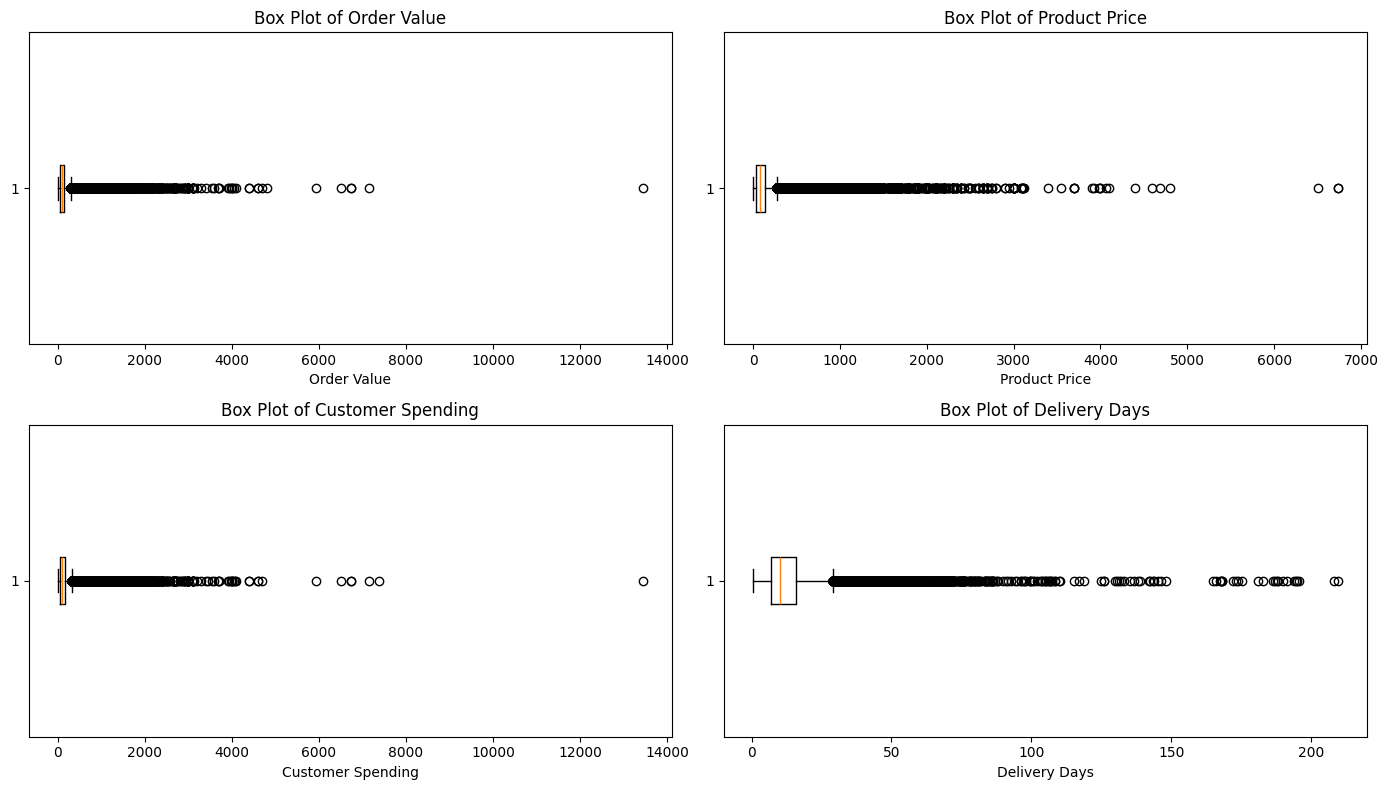

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (name, values) in zip(axes.flatten(), analysis_variables.items()):
    ax.boxplot(values, vert=False)
    ax.set_title(f"Box Plot of {name}")
    ax.set_xlabel(name)

plt.tight_layout()
plt.show()

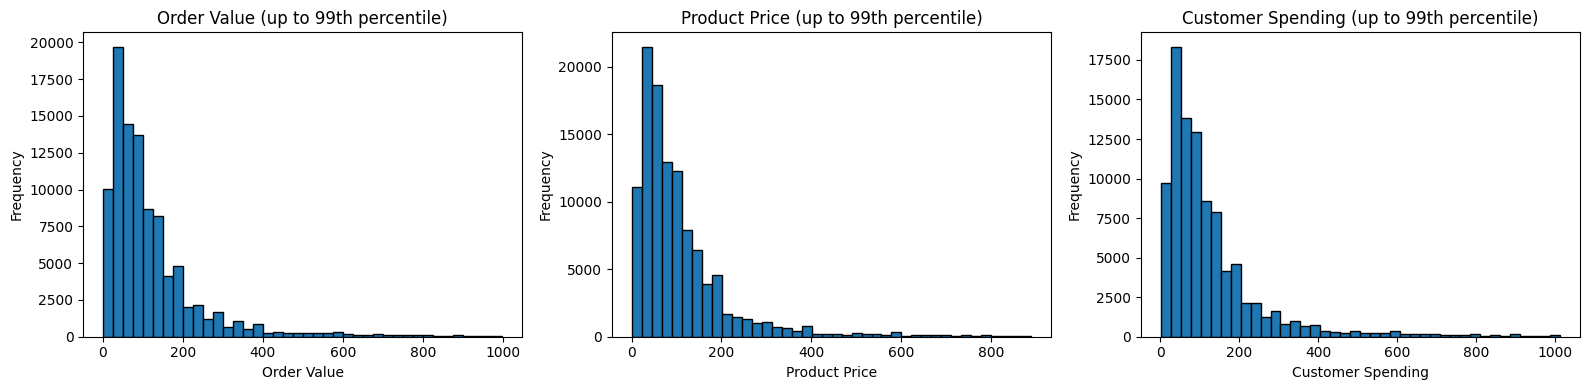

In [17]:
skewed_variables = {
    "Order Value": analysis_variables["Order Value"],
    "Product Price": analysis_variables["Product Price"],
    "Customer Spending": analysis_variables["Customer Spending"]
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, values) in zip(axes, skewed_variables.items()):
    upper_limit = values.quantile(0.99)
    visible_values = values[values <= upper_limit]

    ax.hist(visible_values, bins=40, edgecolor="black")
    ax.set_title(f"{name} (up to 99th percentile)")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

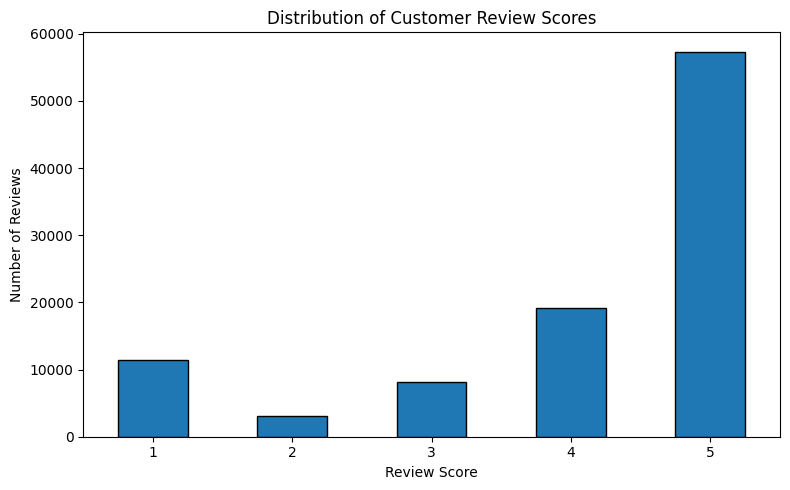

Review percentages:


,Percentage
review_score,
1,11.51
2,3.18
3,8.24
4,19.29
5,57.78


In [18]:
review_counts = (
    review_data["review_score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

review_counts.plot(
    kind="bar",
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Review percentages:")
display(
    (review_counts / review_counts.sum() * 100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)

### 2.7 Distribution Analysis: Interpretation and Key Findings

**1. Order Value Distribution**

The order value distribution is concentrated on the left side of the graph, with a long tail toward higher values. One order value is approximately 14,000, while four other values fall between 6,000 and 8,000. These values may represent genuine high-value orders rather than errors. Therefore, they should be investigated before being classified as outliers or removed.

**2. Product Price Distribution**

Most product prices are concentrated at lower values, while a few products have much higher prices. Two products have prices between 6,000 and 7,000. These observations may be genuine expensive products. The distribution is strongly right-skewed, meaning that a small number of expensive products increase the average price.

**3. Customer Spending Distribution**

Customer spending is concentrated at lower values, with a long tail toward higher spending. One customer has spending of approximately 14,000, and some customers have spending between 6,000 and 8,000. These customers may have purchased expensive products or placed multiple orders. Their spending should be checked before deciding whether the values are unusual or incorrect.

**4. Delivery Time Distribution**

The delivery time distribution shows substantial variation, and potential outliers are difficult to identify clearly from the graph. Most deliveries appear to take less time than the most extreme cases. Some orders may have experienced unusually long delivery delays. Further investigation is required to understand these observations and determine whether they reflect genuine delays or data-quality issues.

**5. Customer Review Score Distribution**

The review score distribution shows that most customers provided positive ratings. Approximately 57.78% of reviews received 5 stars, and 19.29% received 4 stars. In contrast, 11.51% received 1 star, 3.18% received 2 stars, and 8.24% received 3 stars. Overall, the results indicate high customer satisfaction, although the lower ratings suggest that some customer experiences need improvement.

**Overall Conclusion**

The analysis shows that order values, product prices, and customer spending are strongly right-skewed, with most observations concentrated at lower values and a few unusually high values. Delivery times show considerable variation, while customer reviews are generally positive. Extreme values should not be removed automatically because they may represent genuine business transactions. Further investigation will help determine their effect on the statistical analysis and business conclusions.

## Correlation Analysis

In [21]:
correlation_data = review_data[
    ["order_id", "review_score"]
].merge(
    order_analysis[["order_id", "total_order_value"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

correlation_data = correlation_data.merge(
    delivered_orders[["order_id", "delivery_days"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

correlation_data = correlation_data.dropna(
    subset=["review_score", "total_order_value", "delivery_days"]
)

print("Correlation dataset shape:", correlation_data.shape)
display(correlation_data.head())

Correlation dataset shape: (96353, 4)


,order_id,review_score,total_order_value,delivery_days
0,73fc7af87114b39712e6da79b0a377eb,4,370.00,6.133241
1,a548910a1c6147796b98fdf73dbeba33,5,79.79,9.452789
2,f9e4b658b201a9f2ecdecbb34bed034b,5,149.00,13.314190
3,658677c97b385a9be170737859d3511b,5,179.99,10.644005
4,8e6bfb81e283fa7e4f11123a3fb894f1,5,1199.00,18.232315


In [22]:
# Calculate the correlation matrix

correlation_columns = [
    "total_order_value",
    "delivery_days",
    "review_score"
]

correlation_matrix = correlation_data[
    correlation_columns
].corr(method="pearson")

display(correlation_matrix.round(3))

,total_order_value,delivery_days,review_score
total_order_value,1.000,0.055,-0.035
delivery_days,0.055,1.000,-0.334
review_score,-0.035,-0.334,1.000


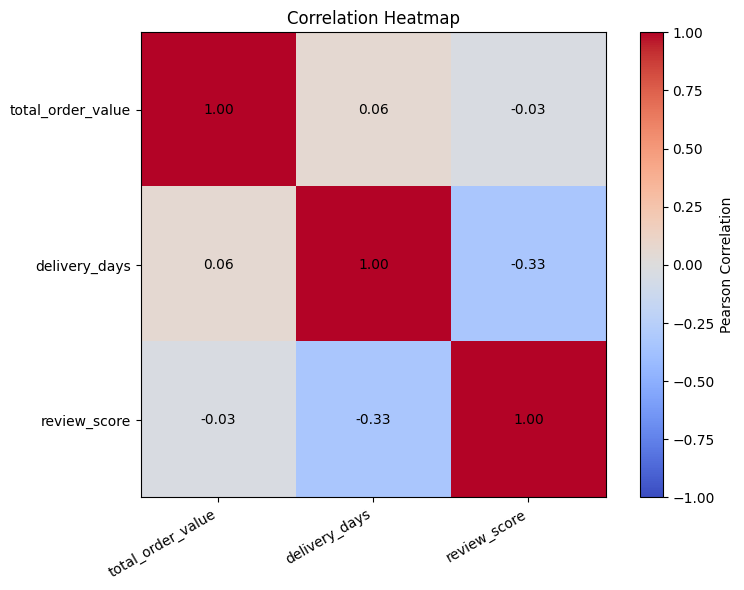

In [23]:
# Visualize correlations with a heatmap

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(correlation_columns, rotation=30, ha="right")
ax.set_yticklabels(correlation_columns)

for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlation Heatmap")
fig.colorbar(image, ax=ax, label="Pearson Correlation")

plt.tight_layout()
plt.show()

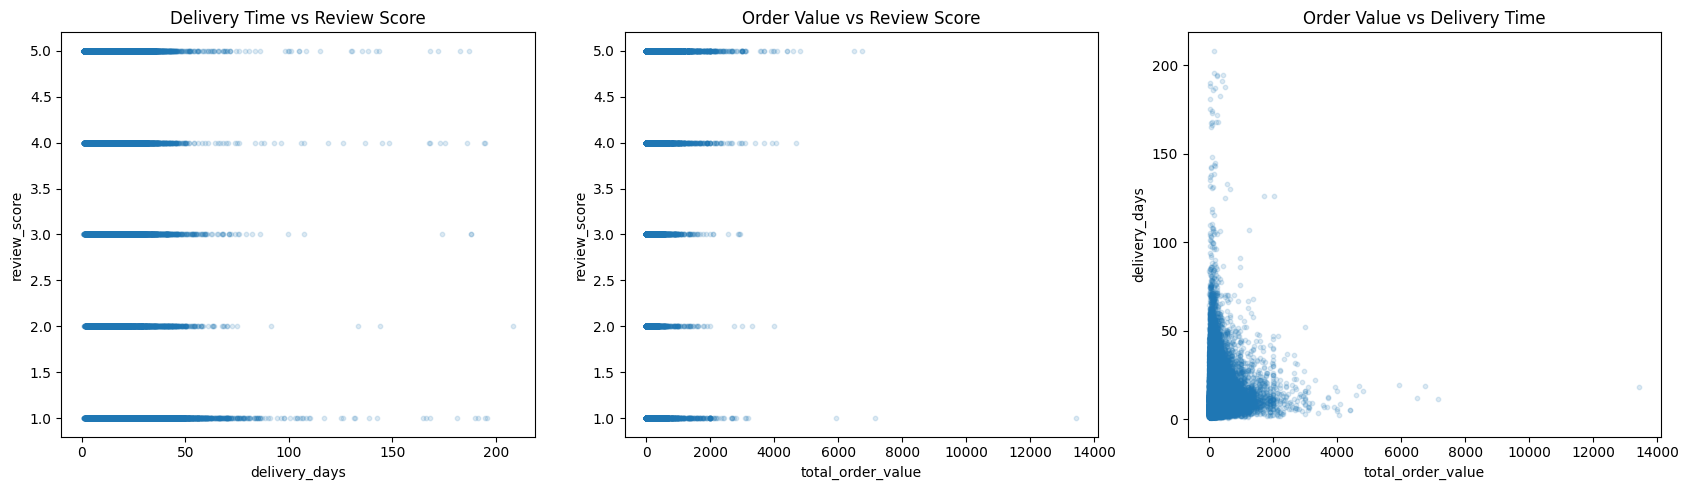

In [24]:
# Plot relationships between the variables

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

plot_pairs = [
    (
        "delivery_days",
        "review_score",
        "Delivery Time vs Review Score"
    ),
    (
        "total_order_value",
        "review_score",
        "Order Value vs Review Score"
    ),
    (
        "total_order_value",
        "delivery_days",
        "Order Value vs Delivery Time"
    )
]

for ax, (x_col, y_col, title) in zip(axes, plot_pairs):
    ax.scatter(
        correlation_data[x_col],
        correlation_data[y_col],
        alpha=0.15,
        s=10
    )

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [25]:
# Save correlation results

from pathlib import Path

output_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "correlation_matrix.csv"

correlation_matrix.to_csv(output_file)

print("Correlation matrix saved to:")
print(output_file)

Correlation matrix saved to:
C:\Users\LATO\Documents\Sales Analysis\Analysis Tables\correlation_matrix.csv


### 3.7 Correlation Analysis: Interpretation and Key Findings

**1. Delivery Time vs. Review Score**

The Pearson correlation coefficient between delivery time and review score is **−0.334**. This indicates a moderate negative linear relationship. In general, longer delivery times are associated with lower customer review scores. This suggests that delivery performance may be an important factor in customer satisfaction, although correlation alone does not prove causation.

**2. Order Value vs. Review Score**

The correlation coefficient between order value and review score is **−0.035**. This indicates a very weak negative linear relationship, which is close to zero. Therefore, order value has little linear association with customer review scores in this dataset.

**3. Order Value vs. Delivery Time**

The correlation coefficient between order value and delivery time is **0.055**. This indicates a very weak positive linear relationship. Higher-value orders are not meaningfully associated with longer delivery times based on this correlation.

**4. Scatter Plot Interpretation**

Most observations are concentrated on the left side of the scatter plots, while a smaller number of high-value orders and longer delivery times extend across the graphs. This pattern is consistent with the skewed distributions observed in Step 2. The scatter plots should be interpreted carefully because extreme values can make the main pattern difficult to see.

**Overall Conclusion**

The strongest relationship among the three pairs is between delivery time and review score, with a correlation of −0.334. The relationships involving order value are very weak. These results suggest that delivery performance deserves further investigation when studying customer satisfaction. Additional statistical testing is needed to determine whether the observed relationship between delivery time and review score is statistically significant.

### Hypothesis Testing

In [26]:
# Import statistical testing tools
import pandas as pd
import numpy as np
from scipy import stats
from pathlib import Path

# Combine order-level review, order value, and delivery information
test_data = order_reviews[
    ["order_id", "order_review_score"]
].merge(
    order_analysis[["order_id", "total_order_value"]],
    on="order_id",
    how="inner",
    validate="one_to_one"
).merge(
    delivered_orders[["order_id", "delivery_days"]],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Keep records with all required measurements
test_data = test_data.dropna(
    subset=[
        "order_review_score",
        "total_order_value",
        "delivery_days"
    ]
)

print("Observations available:", len(test_data))
display(test_data.head())

Observations available: 95824


,order_id,order_review_score,total_order_value,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,58.90,7.614421
1,00018f77f2f0320c557190d7a144bdd3,4.0,239.90,16.216181
2,000229ec398224ef6ca0657da4fc703e,5.0,199.00,7.948437
3,00024acbcdf0a6daa1e931b038114c75,4.0,12.99,6.147269
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,199.90,25.114352


## Hypotheses:
- \(H_0\): There is no monotonic association between delivery time and review score.
- \(H_1\): There is a monotonic association between delivery time and review score.
Use a 5% significance level (\(\alpha = 0.05\)).
we'll use Spearman's rank correlation test

In [27]:
# Spearman correlation hypothesis test

spearman_result = stats.spearmanr(
    test_data["delivery_days"],
    test_data["order_review_score"]
)

rho = spearman_result.statistic
p_value = spearman_result.pvalue

print("Spearman correlation:", round(rho, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association.")

Spearman correlation: -0.2348
P-value: 0.0
Decision: Reject the null hypothesis.
There is statistically significant evidence of an association.


## 4.4 — Compare delivery times for low-rated and high-rated orders
Now we'll investigate whether orders with lower reviews have different delivery times from orders with higher reviews.
We'll define:
- Low-rated orders: Review scores 1 or 2.
- High-rated orders: Review scores 4 or 5.
- Review score 3 is excluded from this particular comparison.
Because delivery times can be skewed and contain outliers, we'll use the Mann–Whitney U test, a nonparametric test comparing the distributions of two independent groups.
Hypotheses:
- \(H_0\): The delivery-time distributions are the same in the two groups.
- \(H_1\): The delivery-time distributions differ between the two groups.

In [28]:
# Compare delivery times by review group

low_rated = test_data.loc[
    test_data["order_review_score"] <= 2,
    "delivery_days"
]

high_rated = test_data.loc[
    test_data["order_review_score"] >= 4,
    "delivery_days"
]

print("Low-rated orders:", len(low_rated))
print("High-rated orders:", len(high_rated))

print("\nMedian delivery time:")
print("Low-rated:", round(low_rated.median(), 2), "days")
print("High-rated:", round(high_rated.median(), 2), "days")

u_statistic, p_value_delivery = stats.mannwhitneyu(
    low_rated,
    high_rated,
    alternative="two-sided"
)

print("\nMann–Whitney U statistic:", u_statistic)
print("P-value:", p_value_delivery)

if p_value_delivery < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("The delivery-time distributions differ significantly.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a distribution difference.")

Low-rated orders: 12236
High-rated orders: 75619

Median delivery time:
Low-rated: 15.72 days
High-rated: 9.64 days

Mann–Whitney U statistic: 641602978.5
P-value: 0.0
Decision: Reject the null hypothesis.
The delivery-time distributions differ significantly.


In [29]:
# Compare order values by review group

low_value_group = test_data.loc[
    test_data["order_review_score"] <= 2,
    "total_order_value"
]

high_value_group = test_data.loc[
    test_data["order_review_score"] >= 4,
    "total_order_value"
]

print("Median order value:")
print("Low-rated:", round(low_value_group.median(), 2))
print("High-rated:", round(high_value_group.median(), 2))

u_statistic_value, p_value_value = stats.mannwhitneyu(
    low_value_group,
    high_value_group,
    alternative="two-sided"
)

print("\nMann–Whitney U statistic:", u_statistic_value)
print("P-value:", p_value_value)

if p_value_value < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("The order-value distributions differ significantly.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a distribution difference.")

Median order value:
Low-rated: 98.0
High-rated: 84.9

Mann–Whitney U statistic: 502589193.0
P-value: 3.5273143576714673e-53
Decision: Reject the null hypothesis.
The order-value distributions differ significantly.


In [30]:
# Summarize the three hypothesis tests

hypothesis_results = pd.DataFrame([
    {
        "Test": "Spearman: Delivery Time vs Review Score",
        "Statistic": rho,
        "P_Value": spearman_result.pvalue
    },
    {
        "Test": "Mann–Whitney: Delivery Time by Review Group",
        "Statistic": u_statistic,
        "P_Value": p_value_delivery
    },
    {
        "Test": "Mann–Whitney: Order Value by Review Group",
        "Statistic": u_statistic_value,
        "P_Value": p_value_value
    }
])

hypothesis_results["Significance"] = np.where(
    hypothesis_results["P_Value"] < 0.05,
    "Statistically significant",
    "Not statistically significant"
)

display(hypothesis_results.round(4))

,Test,Statistic,P_Value,Significance
0,Spearman: Delivery Time vs Review Score,-2.348000e-01,0.0,Statistically significant
1,Mann–Whitney: Delivery Time by Review Group,6.416030e+08,0.0,Statistically significant
2,Mann–Whitney: Order Value by Review Group,5.025892e+08,0.0,Statistically significant


In [31]:
# Save hypothesis-testing results

output_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

output_dir.mkdir(parents=True, exist_ok=True)

hypothesis_results.to_csv(
    output_dir / "hypothesis_testing_results.csv",
    index=False
)

print("Saved:", output_dir / "hypothesis_testing_results.csv")

Saved: C:\Users\LATO\Documents\Sales Analysis\Analysis Tables\hypothesis_testing_results.csv


### Hypothesis Testing: Interpretation and Key Findings

**1. Delivery Time vs. Review Score — Spearman Correlation Test**

The Spearman correlation coefficient is **−0.2348**, with a p-value below 0.001. Therefore, we reject the null hypothesis. The results indicate a statistically significant negative association between delivery time and review score. In general, longer delivery times tend to be associated with lower customer ratings. However, this relationship does not prove that delivery delays directly cause lower ratings.

**2. Delivery Time by Review Group — Mann–Whitney U Test**

The median delivery time for low-rated orders (scores 1–2) is **15.72 days**, compared with **9.64 days** for high-rated orders (scores 4–5). The Mann–Whitney U test gives a p-value below 0.001, so we reject the null hypothesis. The delivery-time distributions differ statistically between the two groups. The results suggest that low-rated orders tend to have longer delivery times than high-rated orders.

**3. Order Value by Review Group — Mann–Whitney U Test**

The median order value for low-rated orders is **98.00**, compared with **84.90** for high-rated orders. The p-value is approximately \(3.53 \times 10^{-53}\), which is below 0.05. Therefore, we reject the null hypothesis that the two groups have the same order-value distribution. The results indicate a statistically significant difference between the groups. However, the difference in medians does not establish that order value causes lower customer ratings.

**Overall Conclusion**

All three hypothesis tests provide statistically significant evidence of associations or group differences. The clearest practical finding is that low-rated orders have a higher median delivery time than high-rated orders. Order value also differs between the review groups, with low-rated orders having a higher median value. These findings may help the business investigate delivery performance and customer experiences. Statistical significance does not necessarily imply a large practical effect, and other factors may influence review scores.

## Confidence Intervals

In [32]:
import pandas as pd
import numpy as np
from scipy import stats

In [33]:
# Prepare the data for each metric
metrics = {
    "Average Order Value (BRL)": order_analysis["total_order_value"].dropna(),
    "Average Delivery Time (Days)": delivered_orders["delivery_days"].dropna(),
    "Average Review Score": order_reviews["order_review_score"].dropna()
}

# Calculate 95% confidence intervals
confidence_results = []

for metric_name, values in metrics.items():
    n = len(values)
    mean_value = values.mean()
    standard_error = stats.sem(values)

    # Critical t-value for a 95% confidence interval
    critical_value = stats.t.ppf(0.975, df=n - 1)

    margin_of_error = critical_value * standard_error

    lower_bound = mean_value - margin_of_error
    upper_bound = mean_value + margin_of_error

    confidence_results.append({
        "Metric": metric_name,
        "Sample Size": n,
        "Sample Mean": mean_value,
        "Lower 95% CI": lower_bound,
        "Upper 95% CI": upper_bound,
        "Margin of Error": margin_of_error
    })

# Display the results
confidence_intervals = pd.DataFrame(confidence_results)

display(confidence_intervals.round(3))

,Metric,Sample Size,Sample Mean,Lower 95% CI,Upper 95% CI,Margin of Error
0,Average Order Value (BRL),98666,137.754,136.440,139.068,1.314
1,Average Delivery Time (Days),96470,12.558,12.498,12.618,0.060
2,Average Review Score,98673,4.087,4.078,4.095,0.008


In [34]:
confidence_intervals.to_csv(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables\confidence_intervals.csv",
    index=False
)

print("Confidence interval results saved successfully.")

Confidence interval results saved successfully.


### Confidence Interval Analysis — Interpretation

1. **Average Order Value:** The mean order value is R$137.754, with a 95% confidence interval from R$136.440 to R$139.068.

2. **Average Delivery Time:** The mean delivery time is 12.558 days, with a 95% confidence interval from 12.498 to 12.618 days.

3. **Average Review Score:** The mean review score is 4.087, with a 95% confidence interval from 4.078 to 4.095.

4. **Precision:** All three intervals are relatively narrow, indicating precise estimates of the means under the assumptions of the method.

**Conclusion:** These confidence intervals quantify uncertainty around average order value, delivery time, and review score. They can help businesses understand typical performance and evaluate areas for improvement.

### Group Comparisons

In [35]:
# Keep only complete observations
group_data = test_data[
    ["order_id", "order_review_score", "total_order_value", "delivery_days"]
].dropna().copy()

# Create review groups
group_data["review_group"] = np.select(
    [
        group_data["order_review_score"] <= 2,
        group_data["order_review_score"] == 3,
        group_data["order_review_score"] >= 4
    ],
    [
        "Low Rating (1–2)",
        "Medium Rating (3)",
        "High Rating (4–5)"
    ],
    default="Unknown"
)

display(group_data.head())
print("Number of observations:", len(group_data))

,order_id,order_review_score,total_order_value,delivery_days,review_group
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,58.90,7.614421,High Rating (4–5)
1,00018f77f2f0320c557190d7a144bdd3,4.0,239.90,16.216181,High Rating (4–5)
2,000229ec398224ef6ca0657da4fc703e,5.0,199.00,7.948437,High Rating (4–5)
3,00024acbcdf0a6daa1e931b038114c75,4.0,12.99,6.147269,High Rating (4–5)
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,199.90,25.114352,High Rating (4–5)


Number of observations: 95824


In [43]:
review_group_summary = (
    group_data.groupby("review_group", observed=True)
    .agg(
        Number_of_Orders=("order_id", "nunique"),
        Average_Delivery_Days=("delivery_days", "mean"),
        Median_Delivery_Days=("delivery_days", "median"),
        Average_Order_Value=("total_order_value", "mean"),
        Median_Order_Value=("total_order_value", "median"),
        Average_Review_Score=("order_review_score", "mean")
    )
    .reset_index()
)

display(review_group_summary.round(2))

,review_group,Number_of_Orders,Average_Delivery_Days,Median_Delivery_Days,Average_Order_Value,Median_Order_Value,Average_Review_Score
0,High Rating (4–5),75619,11.09,9.64,134.00,84.90,4.75
1,Low Rating (1–2),12236,20.22,15.72,160.19,98.00,1.24
2,Medium Rating (3),7915,14.24,12.04,127.50,82.99,3.00


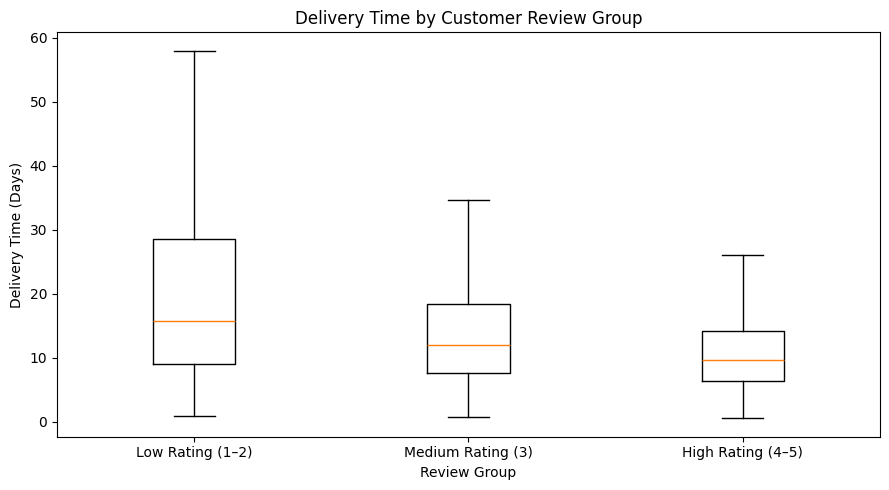

In [44]:
import matplotlib.pyplot as plt

review_order = [
    "Low Rating (1–2)",
    "Medium Rating (3)",
    "High Rating (4–5)"
]

delivery_groups = [
    group_data.loc[
        group_data["review_group"] == group,
        "delivery_days"
    ]
    for group in review_order
]

plt.figure(figsize=(9, 5))
plt.boxplot(delivery_groups, tick_labels=review_order, showfliers=False)
plt.title("Delivery Time by Customer Review Group")
plt.xlabel("Review Group")
plt.ylabel("Delivery Time (Days)")
plt.tight_layout()
plt.show()

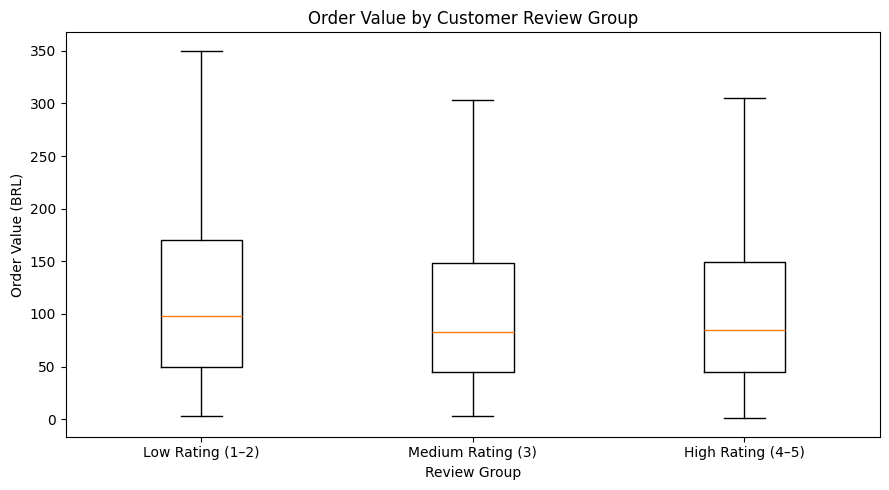

In [38]:
value_groups = [
    group_data.loc[
        group_data["review_group"] == group,
        "total_order_value"
    ]
    for group in review_order
]

plt.figure(figsize=(9, 5))
plt.boxplot(value_groups, tick_labels=review_order, showfliers=False)
plt.title("Order Value by Customer Review Group")
plt.xlabel("Review Group")
plt.ylabel("Order Value (BRL)")
plt.tight_layout()
plt.show()

In [45]:
value_cutoff = group_data["total_order_value"].median()

group_data["value_group"] = np.where(
    group_data["total_order_value"] <= value_cutoff,
    "Lower-Value Orders",
    "Higher-Value Orders"
)

value_group_summary = (
    group_data.groupby("value_group", observed=True)
    .agg(
        Number_of_Orders=("order_id", "nunique"),
        Average_Order_Value=("total_order_value", "mean"),
        Median_Order_Value=("total_order_value", "median"),
        Average_Delivery_Days=("delivery_days", "mean"),
        Median_Delivery_Days=("delivery_days", "median")
    )
    .reset_index()
)

display(value_group_summary.round(2))

,value_group,Number_of_Orders,Average_Order_Value,Median_Order_Value,Average_Delivery_Days,Median_Delivery_Days
0,Higher-Value Orders,47885,227.54,149.9,13.19,10.91
1,Lower-Value Orders,47885,46.08,45.9,11.83,9.68


In [46]:
lower_value_delivery = group_data.loc[
    group_data["value_group"] == "Lower-Value Orders",
    "delivery_days"
]

higher_value_delivery = group_data.loc[
    group_data["value_group"] == "Higher-Value Orders",
    "delivery_days"
]

u_statistic_value_delivery, p_value_value_delivery = stats.mannwhitneyu(
    lower_value_delivery,
    higher_value_delivery,
    alternative="two-sided"
)

print(f"U statistic: {u_statistic_value_delivery:.2f}")
print(f"P-value: {p_value_value_delivery:.6g}")

if p_value_value_delivery < 0.05:
    print("Conclusion: Delivery-time distributions differ significantly.")
else:
    print("Conclusion: Insufficient evidence of a difference in delivery-time distributions.")

U statistic: 1029098534.00
P-value: 8.92534e-166
Conclusion: Delivery-time distributions differ significantly.


In [47]:
output_folder = r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"

review_group_summary.to_csv(
    output_folder + r"\review_group_comparison.csv",
    index=False
)

value_group_summary.to_csv(
    output_folder + r"\order_value_group_comparison.csv",
    index=False
)

print("Group comparison tables saved successfully.")

Group comparison tables saved successfully.


### Group Comparisons — Interpretation

**1. Delivery Time and Review Score**

Low-rated orders had a median delivery time of 15.72 days, compared with 9.64 days for high-rated orders. This difference suggests that longer delivery times are associated with lower customer satisfaction.

**2. Order Value and Review Score**

Low-rated orders had a median order value of R$98.00, while high-rated orders had a median of R$84.90. Higher order spending does not necessarily guarantee a better customer experience.

**3. Delivery Time and Order Value**

Higher-value orders had a median delivery time of 10.91 days, compared with 9.69 days for lower-value orders. The Mann–Whitney U test found a statistically significant difference between the delivery-time distributions (p < 0.001).

**Business Recommendations**

- Monitor delayed deliveries because they may be associated with lower review scores.
- Investigate higher-value orders to identify possible delivery challenges.
- Track customer reviews alongside delivery performance.
- Investigate other factors, including seller, product category, and customer location.

**Limitations:** These findings show associations, not causation. Statistical significance does not necessarily indicate a large business impact.

In [42]:
group_data = group_data[
    group_data["review_group"] != "Unknown"
].copy()